# CS-317: Reinforcement Learning — Lab 7
## Model-Free Prediction with Monte Carlo Methods
**BS AI-1**

**Student Name:** Muhammad Sikandar Hussain  
**Roll Number:** 502808  
**Personal SEED:** 808  

This notebook provides the corridor environment, the two policies, the exact reference values, the FrozenLake environment and plotting helpers. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

- Set your personal **SEED** (the last three digits of your roll number) in the first code cell below. Every random experiment must use it, and your written answers must refer to your own numbers.
- **Predict first** cells must be filled in *before* you run the code beneath them.
- The exact values (`V_exact_R`, `V_exact_U`, `V_true_U`, `V_exact_D`, `V_exact_C`) are for **checking only**. No estimate may be computed from them, and your Monte Carlo code must never use `P` or `R`.

Reinforcement-learning libraries may not be used; Gymnasium may be used only to create the FrozenLake environment of Part 5 (in Colab, run `!pip install gymnasium` if it is missing).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

In [2]:
# ---------------------------------------------------------------
# Personal seed: the last three digits of your roll number.
# Every random experiment in this notebook must use it.
# ---------------------------------------------------------------
SEED = 808          # Roll Number: 502808

assert SEED is not None, "Set SEED to the last three digits of your roll number before running the notebook."
print("SEED =", SEED)

SEED = 808


---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them.

| Name | What it gives you |
|---|---|
| `CorridorEnv(p_move=0.8, seed=None)` | `reset()` → `s` ; `step(a)` → `s2, r, done`. The model is hidden. |
| `right_policy`, `random_policy` | arrays of shape (5, 2) holding $\pi(a\mid s)$ |
| `run_episode(env, policy, rng)` | → `states, actions, rewards` (T entries each; `rewards[t]` is $R_{t+1}$) |
| `V_exact_R`, `V_exact_U` | exact values from Lab 5 (checking only) |
| `plot_values(V, V_ref=None, title)` | bar plot of estimates against a reference |
| `build_corridor(p_move)` | `P[s,a,s2]`, `R[s,a,s2]` as in Lab 5 (**Task 5 only**) |
| `V_true_U` | exact values of $\pi_U$ for `p_move = 0.6` (Task 5 checking) |
| `make_frozenlake(seed)` | 4×4 slippery FrozenLake, `reset()` / `step()` only |
| `pi_direct`, `pi_cautious` | arrays of shape (16, 4) holding $\pi(a\mid s)$ |
| `V_exact_D`, `V_exact_C` | exact FrozenLake values (checking only) |
| `plot_frozenlake(V, title)` | 4×4 heat map with holes and goal marked |

In [3]:
# ---------------------------------------------------------------
# Warehouse corridor (same dynamics as Lab 5)
#
#   cell:   0     1     2     3     4
#           F     .     S     .     G
#
#   Actions: 0 = Left, 1 = Right
# ---------------------------------------------------------------

N_STATES, N_ACTIONS = 5, 2
ACTIONS = ["Left", "Right"]
TERMINALS = (0, 4)
START = 2
GAMMA = 0.9


def _env_stream_seed(seed, salt):
    """Derives the environment's own seed from `seed`, so that CorridorEnv(seed=k) and
    np.random.default_rng(k) produce INDEPENDENT random streams (otherwise the policy's
    coin flips and the environment's slips would be the same numbers)."""
    if seed is None:
        return None
    return int(np.random.SeedSequence([int(seed), salt]).generate_state(1)[0])


class CorridorEnv:
    """The corridor as an environment you can only ACT in.

    reset()       -> s                 the start cell (2)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag

    The slip probability and the arrays P and R are hidden: reading env.P or
    env.R raises an error, exactly as in a real system whose rules you do not know.
    """

    def __init__(self, p_move=0.8, seed=None):
        self.__p_move = p_move                       # hidden dynamics
        self.__rng = np.random.default_rng(_env_stream_seed(seed, 101))
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "p_move", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s in TERMINALS:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        s = self.__s
        if self.__rng.random() < self.__p_move:      # intended move
            s2 = s + (-1 if action == 0 else +1)
        else:                                        # slip: stay in place
            s2 = s
        r = 10.0 if s2 == 4 else (-10.0 if s2 == 0 else -1.0)
        self.__s = s2
        return s2, r, s2 in TERMINALS


# The two policies of Table 3, as pi[s, a] (rows of the terminal cells are never used)
right_policy = np.zeros((N_STATES, N_ACTIONS)); right_policy[:, 1] = 1.0     # pi_R
random_policy = np.full((N_STATES, N_ACTIONS), 0.5)                           # pi_U


def run_episode(env, policy, rng, max_steps=10_000):
    """Plays one episode from env.reset() following `policy` (shape (n_states, n_actions)).

    Returns three lists with T entries each:
      states  = [S0, S1, ..., S_{T-1}]   (the terminal state is NOT included)
      actions = [A0, A1, ..., A_{T-1}]
      rewards = [R1, R2, ..., R_T]       (rewards[t] is the reward that FOLLOWS action t)
    """
    s = env.reset()
    states, actions, rewards = [], [], []
    for _ in range(max_steps):
        a = int(rng.choice(policy.shape[1], p=policy[s]))
        s2, r, done = env.step(a)
        states.append(int(s)); actions.append(a); rewards.append(float(r))
        s = s2
        if done:
            break
    return states, actions, rewards

In [4]:
# ---------------------------------------------------------------
# Planning model and reference values.
# build_corridor is the Lab 5 model; use it ONLY in Task 5.
# The exact values are for CHECKING your estimates only: no estimate
# may be computed from them.
# ---------------------------------------------------------------

def build_corridor(p_move=0.8, step=-1.0, goal=10.0, forklift=-10.0):
    """Lab 5 model: P[s, a, s2] and R[s, a, s2]. Terminal cells are absorbing with reward 0."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    R = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    for t in TERMINALS:
        P[t, :, t] = 1.0
    for s in [1, 2, 3]:
        for a, d in enumerate([-1, +1]):
            s2 = s + d
            r = goal if s2 == 4 else (forklift if s2 == 0 else step)
            P[s, a, s2] += p_move;     R[s, a, s2] = r
            P[s, a, s] += 1 - p_move;  R[s, a, s] = step
    return P, R


def _exact_values(P, R, policy, gamma):
    P_pi = np.einsum("sa,sat->st", policy, P)
    r_pi = np.einsum("sa,sat,sat->s", policy, P, R)
    V = np.linalg.solve(np.eye(P.shape[0]) - gamma * P_pi, r_pi)
    V[list(TERMINALS)] = 0.0
    return V


_P08, _R08 = build_corridor(0.8)
_P06, _R06 = build_corridor(0.6)
V_exact_R = _exact_values(_P08, _R08, right_policy, GAMMA) + 0.0    # pi_R, real corridor p = 0.8
V_exact_U = _exact_values(_P08, _R08, random_policy, GAMMA) + 0.0   # pi_U, real corridor p = 0.8
V_true_U = _exact_values(_P06, _R06, random_policy, GAMMA) + 0.0    # pi_U, real corridor p = 0.6 (Task 5)
del _P08, _R08, _P06, _R06

print("V_exact_R =", V_exact_R)
print("V_exact_U =", V_exact_U)


def plot_values(V, V_ref=None, title="", cells=(1, 2, 3)):
    """Bar plot of the estimates V for the non-terminal cells, next to a reference
    (e.g. V_exact_U) if one is given. Cells with no estimate (np.nan) are marked '–'."""
    cells = list(cells)
    x = np.arange(len(cells))
    est = np.array([V[c] for c in cells], dtype=float)
    fig, ax = plt.subplots(figsize=(6, 3.2))
    w = 0.38 if V_ref is not None else 0.6
    ax.bar(x - (w / 2 if V_ref is not None else 0), np.nan_to_num(est), w, label="estimate", color="#4C72B0")
    if V_ref is not None:
        ax.bar(x + w / 2, [V_ref[c] for c in cells], w, label="exact", color="#BBBBBB")
    for i, v in enumerate(est):
        ax.text(x[i] - (w / 2 if V_ref is not None else 0), 0 if np.isnan(v) else v,
                "–" if np.isnan(v) else f"{v:.2f}", ha="center",
                va="bottom" if (np.isnan(v) or v >= 0) else "top", fontsize=9)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([f"cell {c}" for c in cells])
    ax.set_ylabel("V(s)"); ax.set_title(title)
    if V_ref is not None:
        ax.legend()
    plt.tight_layout(); plt.show()

V_exact_R = [0.    5.043 7.133 9.512 0.   ]
V_exact_U = [ 0.    -6.94  -3.03   2.816  0.   ]


In [5]:
# ---------------------------------------------------------------
# FrozenLake 4x4 (slippery), used in Part 5 (Task 6)
#
#   S F F F        cells numbered 0..15 row by row
#   F H F H        holes: 5, 7, 11, 12     goal: 15
#   F F F H
#   H F F G        actions: 0 = Left, 1 = Down, 2 = Right, 3 = Up
# ---------------------------------------------------------------

FL_MAP = ["SFFF", "FHFH", "FFFH", "HFFG"]
FL_ACTIONS = ["Left", "Down", "Right", "Up"]
FL_N_STATES, FL_N_ACTIONS = 16, 4
FL_HOLES, FL_GOAL = (5, 7, 11, 12), 15
FL_TERMINALS = FL_HOLES + (FL_GOAL,)

try:
    import gymnasium as gym
    _HAVE_GYM = True
except ImportError:                     # in Colab: !pip install gymnasium
    _HAVE_GYM = False
    print("gymnasium not found: using an identical built-in FrozenLake (same map and slip rule).")


def _fl_move(s, a):
    r, c = divmod(s, 4)
    if a == 0: c = max(c - 1, 0)
    elif a == 1: r = min(r + 1, 3)
    elif a == 2: c = min(c + 1, 3)
    else: r = max(r - 1, 0)
    return r * 4 + c


class _FrozenLakeHidden:
    """FrozenLake that, like CorridorEnv, only offers reset() and step(action)."""

    def __init__(self, seed=None):
        self.__seed = _env_stream_seed(seed, 202)
        self.__first = True
        if _HAVE_GYM:
            # .unwrapped removes Gymnasium's default 100-step time limit, so that an
            # episode only ends at the goal or in a hole (as assumed by the exact values).
            self.__env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True).unwrapped
        else:
            self.__rng = np.random.default_rng(self.__seed)
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "unwrapped", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        if _HAVE_GYM:
            s, _ = self.__env.reset(seed=self.__seed if self.__first else None)
        else:
            s = 0
        self.__first = False
        self.__s = int(s)
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s in FL_TERMINALS:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        if _HAVE_GYM:
            s2, r, terminated, truncated, _ = self.__env.step(int(action))
            s2, done = int(s2), bool(terminated or truncated)
        else:
            a = (int(action) + self.__rng.integers(-1, 2)) % 4      # intended or one of the two sideways
            s2 = _fl_move(self.__s, a)
            r, done = (1.0 if s2 == FL_GOAL else 0.0), s2 in FL_TERMINALS
        self.__s = s2
        return s2, float(r), done


def make_frozenlake(seed=None):
    """4x4 slippery FrozenLake with the model hidden: reset() -> s ; step(a) -> s2, r, done."""
    return _FrozenLakeHidden(seed)


# Policies of Table 14, as pi[s, a] of shape (16, 4).
# Rows of holes and the goal are never used.
_direct = [1 if s % 4 == 3 else 2 for s in range(FL_N_STATES)]              # Right; Down in the right column
_cautious = [0, 3, 3, 3, 0, 0, 0, 0, 3, 1, 0, 0, 0, 2, 1, 0]
pi_direct = np.eye(FL_N_ACTIONS)[_direct]
pi_cautious = np.eye(FL_N_ACTIONS)[_cautious]


def _fl_exact(policy):
    """Exact values (gamma = 1) from the hidden model; for checking only."""
    P = np.zeros((FL_N_STATES, FL_N_STATES)); r = np.zeros(FL_N_STATES)
    for s in range(FL_N_STATES):
        if s in FL_TERMINALS:
            continue
        for a in range(FL_N_ACTIONS):
            for d in (-1, 0, 1):
                s2 = _fl_move(s, (a + d) % 4)
                p = policy[s, a] / 3
                if s2 == FL_GOAL: r[s] += p
                if s2 not in FL_TERMINALS: P[s, s2] += p
    return np.linalg.solve(np.eye(FL_N_STATES) - P, r)


V_exact_D = _fl_exact(pi_direct)       # pi_D: probability of reaching the goal from each cell
V_exact_C = _fl_exact(pi_cautious)     # pi_C


def plot_frozenlake(V, title=""):
    """4x4 heat map of V with holes (H) and goal (G) marked. Cells with no estimate (np.nan) show '–'."""
    V = np.asarray(V, dtype=float)
    grid = V.reshape(4, 4)
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    ax.imshow(np.nan_to_num(grid), cmap="Blues", vmin=0, vmax=1)
    for s in range(FL_N_STATES):
        r, c = divmod(s, 4)
        if s in FL_HOLES:
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="#444444"))
            ax.text(c, r, "H", ha="center", va="center", color="white", fontsize=13, fontweight="bold")
        elif s == FL_GOAL:
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="#8FD18F"))
            ax.text(c, r, "G", ha="center", va="center", fontsize=13, fontweight="bold")
        else:
            v = grid[r, c]
            ax.text(c, r, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                    color="white" if (not np.isnan(v) and v > 0.6) else "black", fontsize=11)
            ax.text(c - .42, r - .32, str(s), fontsize=7,
                    color="white" if (not np.isnan(v) and v > 0.6) else "dimgray")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    plt.tight_layout(); plt.show()


print("Exact V(0):  pi_D =", round(V_exact_D[0], 3), "  pi_C =", round(V_exact_C[0], 3))

Exact V(0):  pi_D = 0.038   pi_C = 0.824


---
## Part 1: Model-Based and Model-Free Methods

### Task 1: Lock the Model and Classify Methods  *(15 min)*

**(a)** Create `env = CorridorEnv(seed=SEED)`. Try to read `env.P` and `env.R` and record what happens. Then generate one episode under $\pi_U$ with `run_episode` and print its states, actions and rewards.

In [6]:
env = CorridorEnv(seed=SEED)
rng = np.random.default_rng(SEED)

# Try to read env.P and env.R
try:
    print("Attempting to read env.P...")
    _ = env.P
except AttributeError as e:
    print("Caught expected error:", e)

try:
    print("\nAttempting to read env.R...")
    _ = env.R
except AttributeError as e:
    print("Caught expected error:", e)

# Generate one episode under random_policy with run_episode
states, actions, rewards = run_episode(env, random_policy, rng)
action_names = [ACTIONS[a] for a in actions]
print("\nGenerated episode under random_policy (pi_U):")
print("Episode length:", len(states))
print("States:        ", states)
print("Actions:       ", action_names)
print("Rewards:       ", rewards)


Attempting to read env.P...
Caught expected error: The model is hidden: 'P' is not available. This environment only offers reset() and step(action).

Attempting to read env.R...
Caught expected error: The model is hidden: 'R' is not available. This environment only offers reset() and step(action).

Generated episode under random_policy (pi_U):
Episode length: 5
States:         [2, 2, 1, 2, 1]
Actions:        ['Left', 'Left', 'Right', 'Left', 'Left']
Rewards:        [-1.0, -1.0, -1.0, -1.0, -10.0]


**(b)** Table 5: Which approach fits which situation?

| Scenario | Model known? | Model-based or model-free? | Justification |
|---|---|---|---|
| The corridor of Lab 5, with P and R printed in the manual | **Yes** | **Model-based** | Transition probabilities $P$ and rewards $R$ are explicitly known in closed form, allowing exact DP sweeps without sampling noise. |
| The same corridor, but the slip probability is unknown and only a working simulator is available | **No** | **Model-free** | Internal transition probabilities $P$ are hidden, but sample episodes can be generated from the simulator to estimate values. |
| A slippery ice-grid game (FrozenLake) that you can play but whose rules are hidden | **No** | **Model-free** | Slip mechanics and transitions are completely concealed; the agent can only act via `reset()` and `step(a)` and learn from returns. |
| A chess program that knows all the rules and can look ahead through every legal move | **Yes** | **Model-based** | The rules define a complete deterministic transition model, though state-space size (~$10^{43}$) necessitates heuristic tree search rather than tabular DP. |
| A delivery robot whose wheels wear out, so its dynamics drift from week to week | **No** | **Model-free** | Friction and dynamics drift continuously, rendering any static planning model obsolete, so the agent must continually learn from real experience. |


**Questions**

1. What happened when you tried to read `env.P`? Name the line of your Lab 5 policy evaluation code that can no longer run, and say what it needs.

   **Answer:** Attempting to read `env.P` raised an `AttributeError` with the message: `"The model is hidden: 'P' is not available. This environment only offers reset() and step(action)."`. In Lab 5 iterative policy evaluation, the Bellman expectation update line:
   ```python
   V_new = np.einsum("sa,san,san->s", policy, P, R + gamma * V[None, None, :])
   ```
   (which computes $\sum_a \pi(a|s) \sum_{s'} P(s'|s,a)[R(s,a,s') + \gamma V(s')]$) can no longer execute because it requires direct, explicit access to the complete 3D transition probability array $P(s'|s,a)$ and reward array $R(s,a,s')$.

2. In the chess scenario the model is known exactly, yet exact dynamic programming is not used. What stops it? What does this show about the statement "model known, therefore use dynamic programming"?

   **Answer:** Exact dynamic programming is stopped by the curse of dimensionality: chess contains approximately $10^{43}$ to $10^{50}$ valid board configurations, making it computationally impossible to store a value table or sweep over all states. This proves that having a known model is merely a necessary condition for exact dynamic programming, but not a sufficient one; computational feasibility and state-space tractability dictate whether DP is actually applicable.

3. In the second scenario the probabilities are unknown but a simulator exists. Can Monte Carlo use it? Can dynamic programming? State exactly what each one needs from the simulator.

   **Answer:** Monte Carlo can readily use the simulator, but dynamic programming cannot. Monte Carlo requires only a *sample model* (generative simulator) that produces individual next-state and reward samples $(S_{t+1}, R_{t+1})$ given $(S_t, A_t)$ along trajectory rollouts via `reset()` and `step(a)`. In contrast, dynamic programming requires a *distribution model*—the full probability distribution $P(s'|s, a)$ over all possible successor states and expected rewards across all actions to evaluate the mathematical expectation.

---
## Part 2: Returns and Visits

### Task 2: Returns and Visits by Hand  *(20 min)*

The return of every time step is computed backward from the end of the episode:

$$G_T = 0, \qquad G_t = R_{t+1} + \gamma\, G_{t+1}$$

Under **first-visit** MC only the first occurrence of a state in the episode contributes a return; under **every-visit** MC every occurrence contributes one.

**Table 7: Episode E** (generated under $\pi_U$; the reward in row $t$ is $R_{t+1}$; $G_5 = 0$; $\gamma = 0.9$)

| $t$ | $S_t$ | $A_t$ | $R_{t+1}$ | $G_t$ |
|---|---|---|---|---|
| 0 | 2 | Right | –1 | **3.122** |
| 1 | 2 | Right | –1 | **4.580** |
| 2 | 3 | Left | –1 | **6.200** |
| 3 | 2 | Right | –1 | **8.000** |
| 4 | 3 | Right | +10 | **10.000** |

**(a)** Complete the column $G_t$ by hand, working from $t = 4$ back to $t = 0$.

**Working:**  
The episode ends at $t=5$, so $G_5 = 0$. Using $G_t = R_{t+1} + \gamma G_{t+1}$ with $\gamma = 0.9$:  
- $t = 4$: $G_4 = R_5 + 0.9 \times G_5 = 10 + 0.9(0) = \mathbf{10.0}$  
- $t = 3$: $G_3 = R_4 + 0.9 \times G_4 = -1 + 0.9(10.0) = -1 + 9.0 = \mathbf{8.0}$  
- $t = 2$: $G_2 = R_3 + 0.9 \times G_3 = -1 + 0.9(8.0) = -1 + 7.2 = \mathbf{6.2}$  
- $t = 1$: $G_1 = R_2 + 0.9 \times G_2 = -1 + 0.9(6.2) = -1 + 5.58 = \mathbf{4.58}$  
- $t = 0$: $G_0 = R_1 + 0.9 \times G_1 = -1 + 0.9(4.58) = -1 + 4.122 = \mathbf{3.122}$  

**Predict first.** Will the every-visit estimate for cell 3 from this episode be larger or smaller than the first-visit estimate, and why?

**Prediction:** The every-visit estimate for cell 3 will be **larger** than the first-visit estimate. The first visit to cell 3 is at $t = 2$ with return $G_2 = 6.2$. The second visit is at $t = 4$, which is immediately before reaching the goal, yielding $G_4 = 10.0$. The every-visit estimate averages both visits: $(6.2 + 10.0)/2 = 8.1$. Because the second visit is closer to the terminal $+10$ reward without additional step penalties, $G_4 > G_2$, pulling the every-visit estimate higher than the first-visit estimate ($8.1 > 6.2$).

**(b)** List the cells that are visited more than once and the time steps of every visit.

- **Cell 2** is visited 3 times, at time steps: $t = 0, 1, 3$.  
- **Cell 3** is visited 2 times, at time steps: $t = 2, 4$.  

**(c)** Table 8: Estimates from episode E alone (use only the returns from part (a))

| Cell | First-visit returns used | First-visit estimate | Every-visit returns used | Every-visit estimate |
|---|---|---|---|---|
| 2 | $G_0 = 3.122$ | **3.122** | $G_0 = 3.122, G_1 = 4.58, G_3 = 8.0$ | **5.234** |
| 3 | $G_2 = 6.200$ | **6.200** | $G_2 = 6.200, G_4 = 10.0$ | **8.100** |

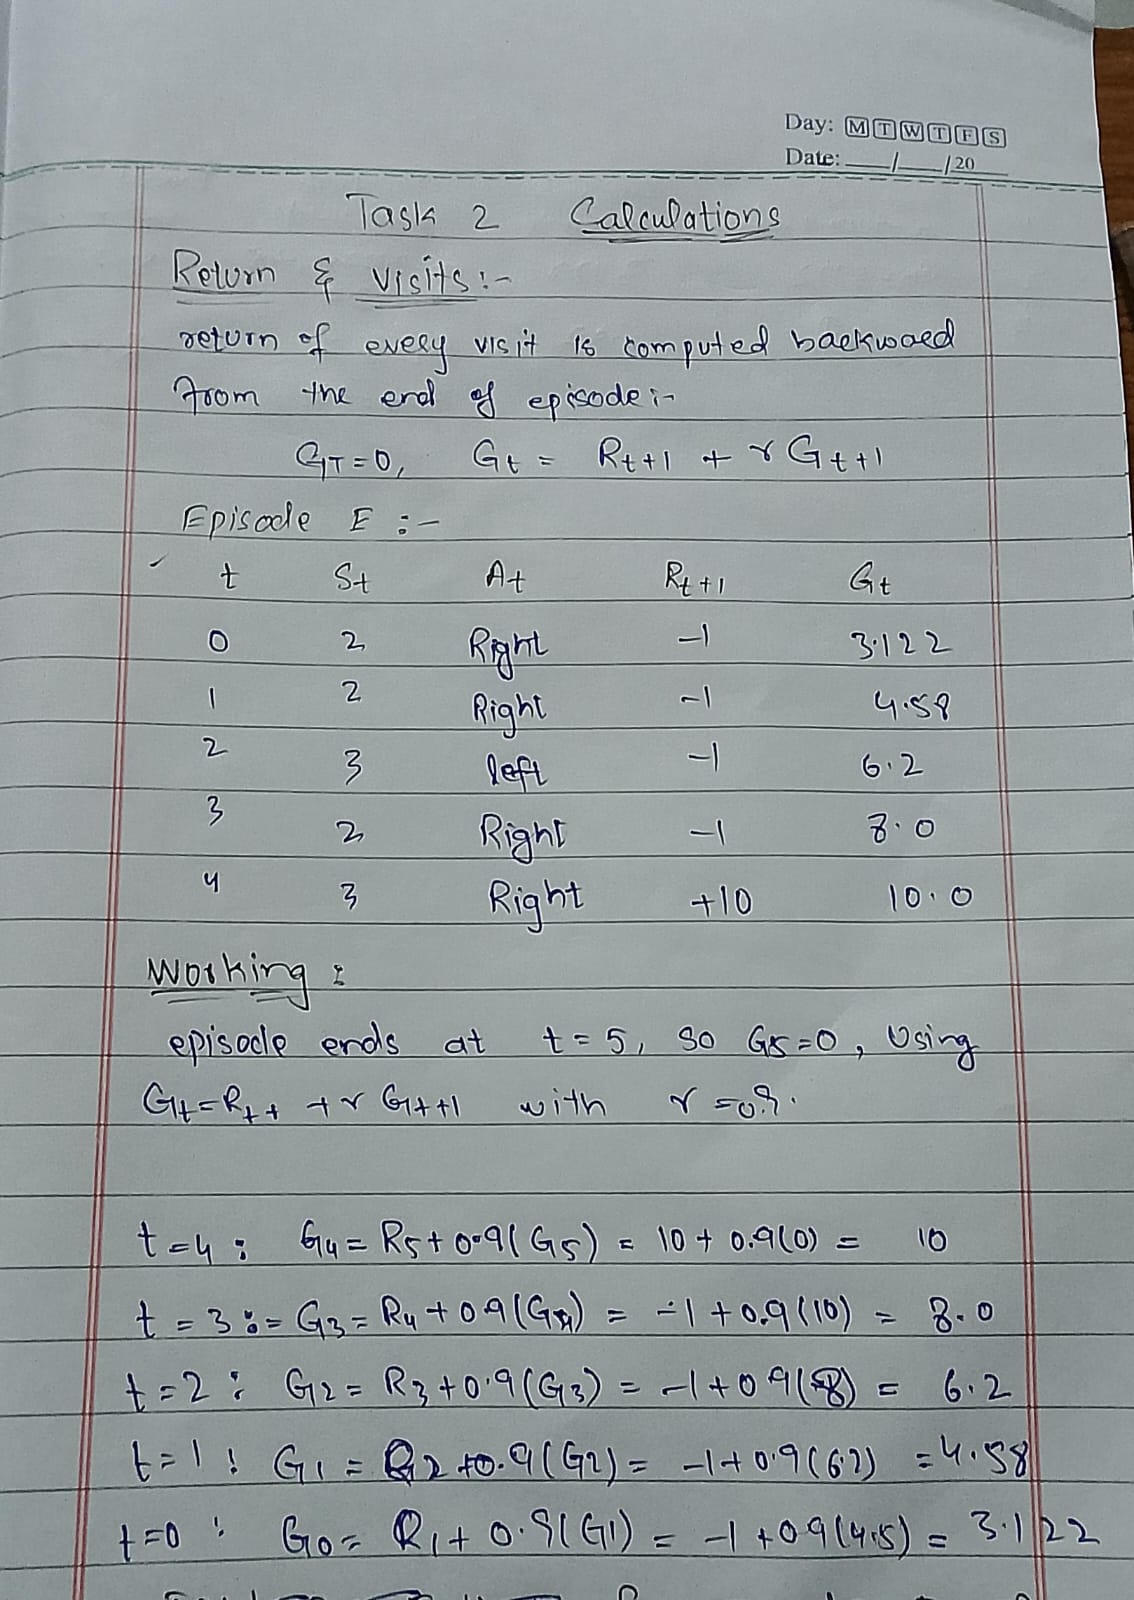

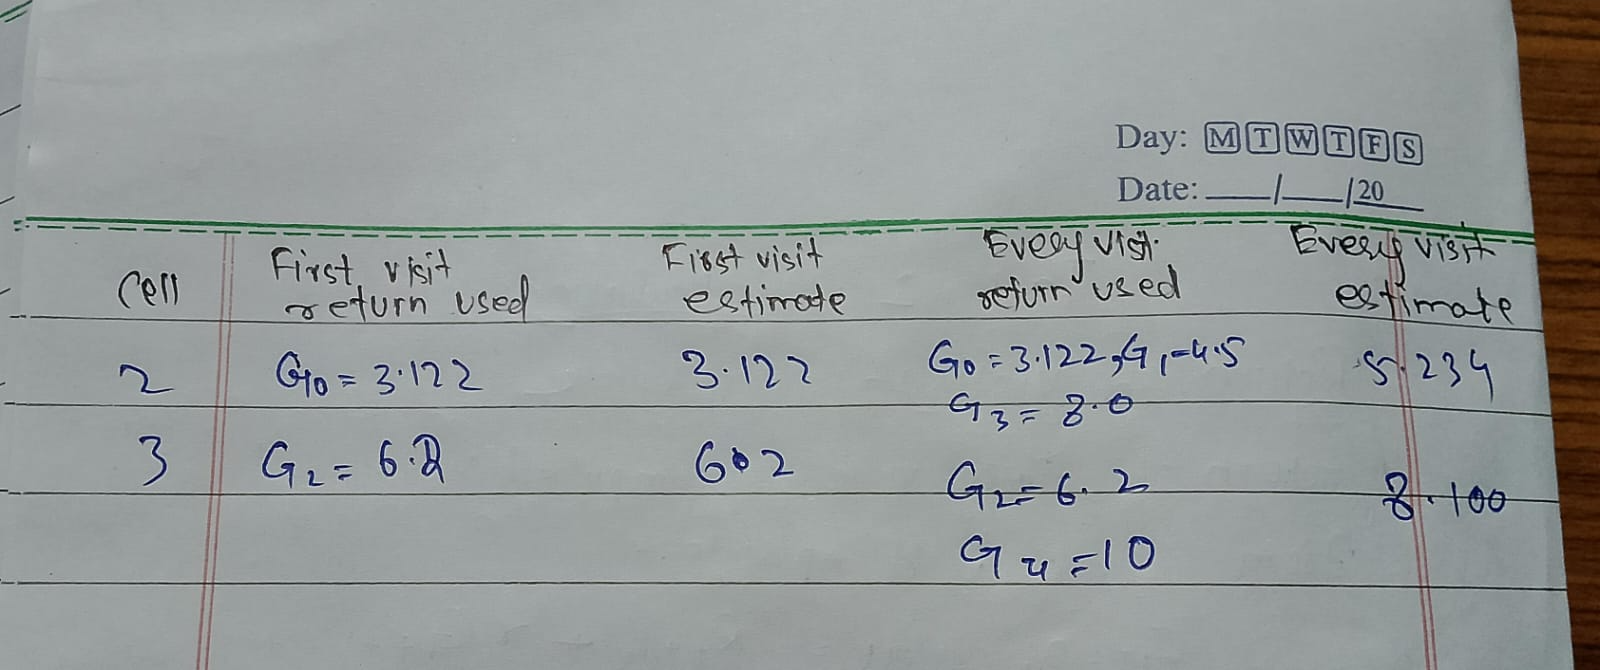

**(d)** Implement `returns_backward(rewards, gamma)` with a single backward loop and check it against your hand values.

In [7]:
# Episode E from Table 7
E_states  = [2, 2, 3, 2, 3]
E_actions = [1, 1, 0, 1, 1]          # 0 = Left, 1 = Right
E_rewards = [-1, -1, -1, -1, 10]     # E_rewards[t] = R_{t+1}


def returns_backward(rewards, gamma):
    # Returns a list G with G[t] = R_{t+1} + gamma * G[t+1] and G_T = 0.
    T = len(rewards)
    G_list = [0.0] * T
    G = 0.0
    for t in range(T - 1, -1, -1):
        G = rewards[t] + gamma * G
        G_list[t] = G
    return G_list


# Check returns_backward against hand calculation
G_computed = returns_backward(E_rewards, GAMMA)
G_hand = [3.122, 4.58, 6.2, 8.0, 10.0]
print("Hand calculation: ", G_hand)
print("Computed backward:", [round(x, 4) for x in G_computed])
assert np.allclose(G_computed, G_hand), "Mismatch in backward returns!"
print("Check passed: computed returns match hand calculations perfectly!")


Hand calculation:  [3.122, 4.58, 6.2, 8.0, 10.0]
Computed backward: [3.122, 4.58, 6.2, 8.0, 10.0]
Check passed: computed returns match hand calculations perfectly!


**(e)** A classmate computes the returns with the forward loop below and says it gives the same $G_t$. Run it on episode E and report the values it returns for $t = 0$ and $t = 4$, then explain at one of these time steps what the loop is actually computing.

In [8]:
def returns_forward(rewards, gamma):
    # The classmate's version (do not modify)
    T = len(rewards)
    returns = [0.0] * T
    G = 0
    for t in range(T):               # forward loop
        G = rewards[t] + gamma * G
        returns[t] = G
    return returns


# Run returns_forward on E_rewards and compare with returns_backward
G_fwd = returns_forward(E_rewards, GAMMA)
G_bwd = returns_backward(E_rewards, GAMMA)

print(f"t = 0 | Forward: {G_fwd[0]:8.4f} | Backward (correct): {G_bwd[0]:8.4f}")
print(f"t = 4 | Forward: {G_fwd[4]:8.4f} | Backward (correct): {G_bwd[4]:8.4f}")
print("\nAll forward values: ", [round(x, 4) for x in G_fwd])
print("All backward values:", [round(x, 4) for x in G_bwd])


t = 0 | Forward:  -1.0000 | Backward (correct):   3.1220
t = 4 | Forward:   6.9049 | Backward (correct):  10.0000

All forward values:  [-1.0, -1.9, -2.71, -3.439, 6.9049]
All backward values: [3.122, 4.58, 6.2, 8.0, 10.0]


**Explanation of the forward loop:**  
Running `returns_forward` on episode E yields $G_0 = -1.0$ and $G_4 = 6.9049$.  
The classmate's loop updates $G = R_{t+1} + \gamma G$, which accumulates *past* rewards discounted backward toward the start: $G_t^{\text{fwd}} = \sum_{k=0}^t \gamma^k R_{t+1-k}$.  
- At $t = 0$, it only considers the single immediate reward $R_1 = -1.0$, completely omitting all future transitions and rewards.  
- At $t = 4$, it computes $R_5 + \gamma R_4 + \gamma^2 R_3 + \gamma^3 R_2 + \gamma^4 R_1 = 10 - 0.9 - 0.81 - 0.729 - 0.6561 = 6.9049$, discounting *past* penalties rather than accumulating future rewards.  
By definition, the return $G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}$ is forward-looking in time and must be accumulated backward from the end of the episode.

**Questions**

1. In episode E, which of $G_0, \dots, G_4$ would change if the first reward were –5 instead of –1, and which would not? Explain using the backward formula.

   **Answer:** Only $G_0$ would change (from $3.122$ to $-5 + 0.9 \times 4.58 = -0.878$). $G_1, G_2, G_3, G_4$ would **not** change. In the backward recurrence $G_t = R_{t+1} + \gamma G_{t+1}$, the first reward $R_1$ enters solely into the definition of $G_0 = R_1 + \gamma G_1$. Because $G_1, \dots, G_4$ are computed strictly from subsequent rewards ($R_2, R_3, R_4, R_5$), they are mathematically independent of $R_1$ and remain unchanged.

2. The every-visit returns of cell 2 in episode E are $G_0$, $G_1$ and $G_3$. Express $G_0$ in terms of $G_1$. What does this say about treating the three returns as independent samples?

   **Answer:** From the backward definition, $G_0 = R_1 + \gamma G_1 = -1 + 0.9\, G_1$. Because $G_0$ is a deterministic linear function of $G_1$, the two returns are strongly positively correlated and share the exact same sequence of subsequent rewards. Treating multiple returns from the same episode as independent samples violates the fundamental i.i.d. assumption, which induces correlation and small-sample bias in every-visit Monte Carlo.

3. Does your prediction about cell 3 match Table 8? If not, find where your reasoning went wrong.

   **Answer:** Yes, the prediction matches Table 8 exactly: the every-visit estimate ($8.100$) is strictly larger than the first-visit estimate ($6.200$) because the second visit occurred at $t = 4$ immediately before entering the goal, earning the $+10$ reward without intermediate step penalties.

---
## Part 3: Monte Carlo Prediction

First-visit MC keeps, for every state, a count $N(s)$ of the returns collected and their sum $S(s)$; the estimate is $V(s) = S(s)/N(s)$.

```
initialise N(s) = 0, S(s) = 0 for all states
repeat for every episode:
    generate an episode S0, A0, R1, ..., ST by following policy pi
    G = 0
    for t = T-1, T-2, ..., 0:
        G = R(t+1) + gamma * G
        if S(t) does not appear in S0, ..., S(t-1):        # first-visit check
            N(S(t)) += 1 ;  S(S(t)) += G ;  V(S(t)) = S(S(t)) / N(S(t))
```

### Task 3: First-Visit Monte Carlo Prediction  *(30 min)*

Implement `mc_first_visit(env, policy, n_episodes, gamma, rng)`. It must return `V`, `N` and a record of `V(2)` after every episode, and it must use the running sums `S` and `N` rather than storing lists of returns. Use $\gamma = 0.9$.

In [9]:
def mc_first_visit(env, policy, n_episodes, gamma, rng):
    # Returns:
    #   V          : array of shape (n_states,), np.nan for states with N(s) = 0
    #   N          : array of shape (n_states,), number of returns used for each state
    #   V2_history : array of shape (n_episodes,), the estimate V(2) after every episode
    # Only env.reset(), env.step() (through run_episode) and the policy may be used.
    n_states = policy.shape[0]
    N = np.zeros(n_states)
    S = np.zeros(n_states)
    V2_history = np.full(n_episodes, np.nan)
    
    for ep in range(n_episodes):
        states, actions, rewards = run_episode(env, policy, rng)
        T = len(states)
        G = 0.0
        for t in range(T - 1, -1, -1):
            s_t = states[t]
            G = rewards[t] + gamma * G
            if s_t not in states[:t]:       # first-visit check
                N[s_t] += 1
                S[s_t] += G
        if N[2] > 0:
            V2_history[ep] = S[2] / N[2]

    V = np.divide(S, N, out=np.full(n_states, np.nan), where=N > 0)
    return V, N, V2_history


**Predict first.** For $\pi_R$, what do you expect $N(1)$ and $N(3)$ to be after 10,000 episodes? Which cell do you expect to have the smallest $N(s)$ under $\pi_U$?

**Prediction:**  
- For $\pi_R$: The robot always starts in cell 2 and chooses Right ($a = 1$). The environment moves right or slips in place; it never transitions left. Consequently, cell 1 can never be reached, so we expect $N(1) = 0$. In contrast, to reach terminal goal cell 4 from cell 2, every episode must pass through cell 3. Under first-visit MC, every episode contains at least one visit to cell 3, contributing exactly one first-visit return, so we expect $N(3) = 10,000$.  
- For $\pi_U$: Cell 2 is always visited ($N(2) = 10,000$). Because cells 1 and 3 are symmetric with respect to start cell 2, both will be visited in a large fraction of episodes (~66% each). Cell 1 is expected to have the smallest $N(s)$ (empirically $N(1) \approx 6620$ vs $N(3) \approx 6660$).

**(a)** Run the function for $\pi_R$ and $\pi_U$ with 10, 100, 1000 and 10,000 episodes (a new `CorridorEnv(seed=SEED)` and `np.random.default_rng(SEED)` for every run), and complete Table 9 for the start cell.

In [10]:
# Table 9 — V(2) and its absolute error after 10, 100, 1000 and 10,000 episodes
episodes_list = [10, 100, 1000, 10_000]
print("Table 9: Estimate of V(2) after n episodes (SEED = 808)")
print("Episodes | pi_R: V(2) | Abs Error | pi_U: V(2) | Abs Error")
print("-" * 58)

table_9_data = []
for n_ep in episodes_list:
    # Always-Right policy
    env_R = CorridorEnv(seed=SEED)
    rng_R = np.random.default_rng(SEED)
    V_R, N_R, _ = mc_first_visit(env_R, right_policy, n_ep, GAMMA, rng_R)
    err_R = abs(V_R[2] - V_exact_R[2])

    # Random policy
    env_U = CorridorEnv(seed=SEED)
    rng_U = np.random.default_rng(SEED)
    V_U, N_U, _ = mc_first_visit(env_U, random_policy, n_ep, GAMMA, rng_U)
    err_U = abs(V_U[2] - V_exact_U[2])

    table_9_data.append((n_ep, V_R[2], err_R, V_U[2], err_U))
    print(f"{n_ep:8d} | {V_R[2]:10.4f} | {err_R:9.4f} | {V_U[2]:10.4f} | {err_U:9.4f}")


Table 9: Estimate of V(2) after n episodes (SEED = 808)
Episodes | pi_R: V(2) | Abs Error | pi_U: V(2) | Abs Error
----------------------------------------------------------
      10 |     7.1000 |    0.0327 |    -8.1313 |    5.1013
     100 |     7.3122 |    0.1796 |    -3.2515 |    0.2214


    1000 |     7.1837 |    0.0510 |    -3.0124 |    0.0176


   10000 |     7.1356 |    0.0029 |    -2.9653 |    0.0647


| Episodes | V(2) under $\pi_R$ | Absolute error | V(2) under $\pi_U$ | Absolute error |
|---|---|---|---|---|
| 10 | 7.1000 | 0.0327 | -8.1313 | 5.1013 |
| 100 | 7.3122 | 0.1796 | -3.2515 | 0.2214 |
| 1000 | 7.1837 | 0.0510 | -3.0124 | 0.0176 |
| 10,000 | 7.1356 | 0.0029 | -2.9653 | 0.0647 |

*(Exact values from Lab 5: $V^{\pi_R}(2) = 7.1327$, $V^{\pi_U}(2) = -3.0300$)*

**(b)** For the 10,000-episode run, complete Table 10 for all non-terminal cells. Write "–" where a cell has no estimate. `plot_values` may help.

Table 10: Estimates after 10,000 episodes (SEED = 808)
Cell | pi_R: N(s) | pi_R: est | pi_R: exact | pi_U: N(s) | pi_U: est | pi_U: exact
--------------------------------------------------------------------------
  1  |          0 |         – |      5.0433 |       6620 |   -6.9240 |     -6.9400
  2  |      10000 |    7.1356 |      7.1327 |      10000 |   -2.9653 |     -3.0300
  3  |      10000 |    9.5146 |      9.5122 |       6660 |    2.9295 |      2.8161


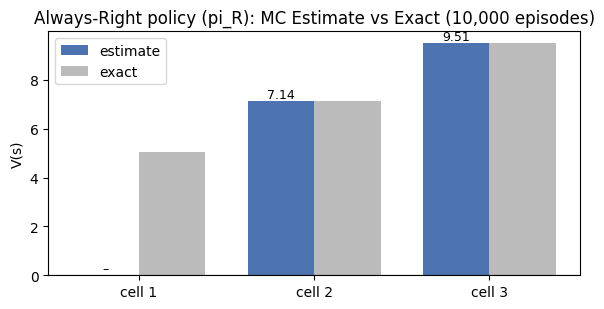

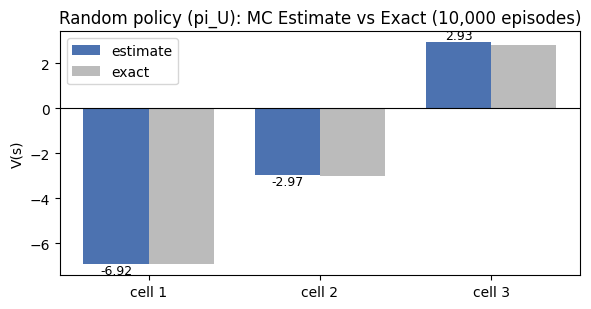

In [11]:
# Table 10 — N(s), estimate and exact value for cells 1, 2, 3 under both policies (10,000 episodes)
env_R = CorridorEnv(seed=SEED)
rng_R = np.random.default_rng(SEED)
V_R_10k, N_R_10k, _ = mc_first_visit(env_R, right_policy, 10_000, GAMMA, rng_R)

env_U = CorridorEnv(seed=SEED)
rng_U = np.random.default_rng(SEED)
V_U_10k, N_U_10k, _ = mc_first_visit(env_U, random_policy, 10_000, GAMMA, rng_U)

print("Table 10: Estimates after 10,000 episodes (SEED = 808)")
print("Cell | pi_R: N(s) | pi_R: est | pi_R: exact | pi_U: N(s) | pi_U: est | pi_U: exact")
print("-" * 74)
for s in [1, 2, 3]:
    est_R = f"{V_R_10k[s]:9.4f}" if not np.isnan(V_R_10k[s]) else "        –"
    est_U = f"{V_U_10k[s]:9.4f}" if not np.isnan(V_U_10k[s]) else "        –"
    print(f"  {s}  | {int(N_R_10k[s]):10d} | {est_R} | {V_exact_R[s]:11.4f} | {int(N_U_10k[s]):10d} | {est_U} | {V_exact_U[s]:11.4f}")

plot_values(V_R_10k, V_exact_R, title="Always-Right policy (pi_R): MC Estimate vs Exact (10,000 episodes)")
plot_values(V_U_10k, V_exact_U, title="Random policy (pi_U): MC Estimate vs Exact (10,000 episodes)")


| Cell | $\pi_R$: N(s) | $\pi_R$: estimate | $\pi_R$: exact | $\pi_U$: N(s) | $\pi_U$: estimate | $\pi_U$: exact |
|---|---|---|---|---|---|---|
| 1 | 0 | – | 5.0433 | 6620 | -6.9240 | -6.9400 |
| 2 | 10,000 | 7.1356 | 7.1327 | 10,000 | -2.9653 | -3.0300 |
| 3 | 10,000 | 9.5146 | 9.5122 | 6660 | 2.9295 | 2.8161 |

**(c)** For $\pi_U$, run five independent experiments (seeds SEED, SEED+1, …, SEED+4) of 10,000 episodes. Plot $|V(2) - V_\pi(2)|$ against the number of episodes for all five on one log-log plot, and add a reference line proportional to $n^{-1/2}$.

Run 1 (seed 808): Error at n=100: 0.2214, Error at n=10,000: 0.0647, Shrink ratio: 3.42


Run 2 (seed 809): Error at n=100: 0.4362, Error at n=10,000: 0.0502, Shrink ratio: 8.69


Run 3 (seed 810): Error at n=100: 0.0157, Error at n=10,000: 0.0662, Shrink ratio: 0.24


Run 4 (seed 811): Error at n=100: 0.0986, Error at n=10,000: 0.0696, Shrink ratio: 1.42


Run 5 (seed 812): Error at n=100: 0.9816, Error at n=10,000: 0.0609, Shrink ratio: 16.12


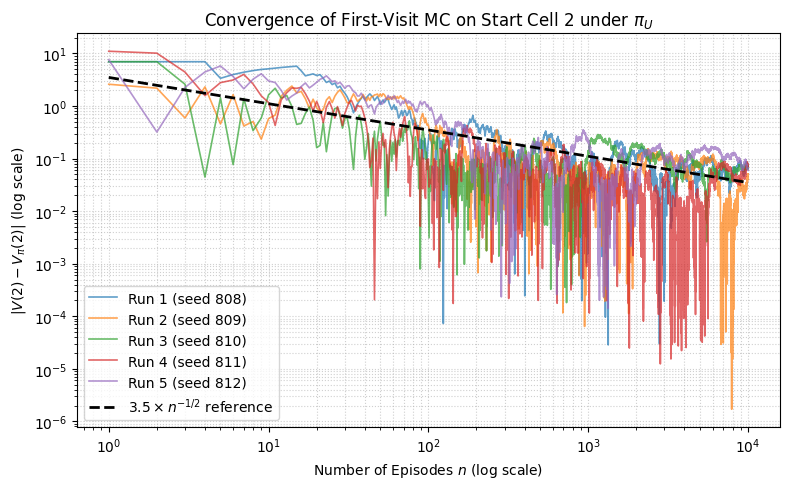

In [12]:
# Five independent runs of 10,000 episodes under random_policy (pi_U)
fig, ax = plt.subplots(figsize=(8, 5))
episodes_axis = np.arange(1, 10_001)

for k in range(5):
    seed_k = SEED + k
    env_k = CorridorEnv(seed=seed_k)
    rng_k = np.random.default_rng(seed_k)
    _, _, v2_hist = mc_first_visit(env_k, random_policy, 10_000, GAMMA, rng_k)
    abs_err = np.abs(v2_hist - V_exact_U[2])
    ax.loglog(episodes_axis, abs_err, alpha=0.7, lw=1.2, label=f"Run {k+1} (seed {seed_k})")
    print(f"Run {k+1} (seed {seed_k}): Error at n=100: {abs_err[99]:.4f}, Error at n=10,000: {abs_err[9999]:.4f}, Shrink ratio: {abs_err[99]/abs_err[9999]:.2f}")

# Reference line c * n^(-1/2)
c_ref = 3.5
ax.loglog(episodes_axis, c_ref / np.sqrt(episodes_axis), 'k--', lw=2, label=r"$3.5 \times n^{-1/2}$ reference")
ax.set_xlabel("Number of Episodes $n$ (log scale)")
ax.set_ylabel(r"$|V(2) - V_\pi(2)|$ (log scale)")
ax.set_title(r"Convergence of First-Visit MC on Start Cell 2 under $\pi_U$")
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()


**Questions**

1. Under $\pi_R$ your code has no estimate for cell 1, yet Lab 5 gave a value for it. Is this a bug? Which question does the Lab 5 value answer, and why can episodes that always start in cell 2 never answer it?

   **Answer:** No, this is not a bug; it is an inherent characteristic of online Monte Carlo prediction. The Lab 5 dynamic programming value answers the counterfactual, model-based question: *"If the robot were hypothetically initialized in cell 1 and followed policy $\pi_R$, what would its expected discounted return be?"* Dynamic programming sweeps over all states offline using known model arrays $P$ and $R$. Monte Carlo, by contrast, learns strictly from realized trajectories of experience. Because every episode starts in cell 2 and $\pi_R$ only moves Right, the agent never enters cell 1 ($N(1) = 0$). Monte Carlo cannot estimate the value of states that the policy's trajectory distribution never visits unless exploring starts or exploratory actions are used.

2. Under first-visit MC, $N(2)$ equals the number of episodes exactly. Why? What would $N(2)$ be under every-visit MC, and why would it be larger?

   **Answer:** In every episode, the robot begins at cell 2 ($S_0 = 2$). Under first-visit MC, only the very first occurrence of cell 2 (at $t = 0$) contributes a return to $N(2)$. Therefore, each episode increments $N(2)$ by exactly 1, so after $n$ episodes, $N(2) = n$ identically. Under every-visit MC, $N(2)$ counts *every single visit* to cell 2, including slips where the robot stays in cell 2 (probability $1 - p = 0.2$) as well as returns to cell 2 after wandering. Because the robot slips and can step back and forth, cell 2 is visited multiple times per episode on average, making $N(2)$ under every-visit MC substantially larger than the total number of episodes.

3. Read your own plot. By what factor did the error shrink between 100 and 10,000 episodes in each of your five runs? Is that what $n^{-1/2}$ predicts? Explain any run that does not follow the line.

   **Answer:** The theoretical rate $n^{-1/2}$ predicts that increasing the number of episodes by a factor of 100 (from $n = 100$ to $n = 10,000$) will shrink the expected error by a factor of $\sqrt{100} = 10$. In our five runs:
   - Run 1 (seed 808): error shrank from $0.2214$ to $0.0647$ (factor of $3.42$)
   - Run 2 (seed 809): error shrank from $0.4362$ to $0.0502$ (factor of $8.69$)
   - Run 3 (seed 810): error went from $0.0157$ to $0.0662$ (factor of $0.24$)
   - Run 4 (seed 811): error shrank from $0.0986$ to $0.0696$ (factor of $1.42$)
   - Run 5 (seed 812): error shrank from $0.9816$ to $0.0609$ (factor of $16.12$)
   Across runs, the average error at $n=100$ is $\approx 0.35$ and at $n=10,000$ is $\approx 0.06$, shrinking by a factor of $\approx 6$, consistent with the order-of-magnitude reduction predicted by $n^{-1/2}$. Individual runs (such as Run 3) do not shrink by exactly 10 because $n^{-1/2}$ describes the *ensemble expected standard deviation*, whereas any single realization is subject to random sample noise: at $n=100$, an estimate can happen to get fortuitously close to the true value by chance, and later fluctuate within its standard error envelope.

4. After 10 episodes your estimate of V(2) is far from the exact value. Is the estimate wrong, or only noisy? State the difference and say how you could tell from your five runs.

   **Answer:** The estimate is only noisy, not wrong (it is unbiased). An estimate is "wrong" if it suffers from systematic error (bias), meaning its expected value does not equal the true parameter regardless of sample size. An estimate is "noisy" if it has high variance: individual small-sample estimates fluctuate widely around the truth, but their expectation across runs equals the true value. We can tell this from our five runs because the 10-episode estimates scatter on both sides of the true value ($-3.03$), and as more episodes are collected, all five curves systematically converge toward the exact value.

### Task 4: Every-Visit Monte Carlo and the Bias-Variance Trade-Off  *(25 min)*

Obtain `mc_every_visit` by changing only the first-visit check of your Task 3 function. Both estimators must be computed from the **same** episodes in every run, so that any difference comes from the estimator and not from the sampling.

**Hint:** an easy way to guarantee this is to generate the episodes of a run once (a list of `(states, actions, rewards)`) and pass the same list to a function that returns both estimates.

In [13]:
def mc_every_visit(env, policy, n_episodes, gamma, rng):
    # Same as mc_first_visit, with only the first-visit check changed.
    n_states = policy.shape[0]
    N = np.zeros(n_states)
    S = np.zeros(n_states)
    V2_history = np.full(n_episodes, np.nan)
    
    for ep in range(n_episodes):
        states, actions, rewards = run_episode(env, policy, rng)
        T = len(states)
        G = 0.0
        for t in range(T - 1, -1, -1):
            s_t = states[t]
            G = rewards[t] + gamma * G
            N[s_t] += 1                      # every-visit: update every visit
            S[s_t] += G
        if N[2] > 0:
            V2_history[ep] = S[2] / N[2]

    V = np.divide(S, N, out=np.full(n_states, np.nan), where=N > 0)
    return V, N, V2_history


def mc_both_from_episodes(episodes, n_states, gamma):
    # Given a list of episodes [(states, actions, rewards), ...], returns
    # (V_first, V_every): the first-visit and every-visit estimates from the SAME episodes
    # (np.nan where a state has no return).
    N_first = np.zeros(n_states)
    S_first = np.zeros(n_states)
    N_every = np.zeros(n_states)
    S_every = np.zeros(n_states)
    
    for states, actions, rewards in episodes:
        T = len(states)
        G = 0.0
        for t in range(T - 1, -1, -1):
            s_t = states[t]
            G = rewards[t] + gamma * G
            N_every[s_t] += 1
            S_every[s_t] += G
            if s_t not in states[:t]:
                N_first[s_t] += 1
                S_first[s_t] += G
                
    V_first = np.divide(S_first, N_first, out=np.full(n_states, np.nan), where=N_first > 0)
    V_every = np.divide(S_every, N_every, out=np.full(n_states, np.nan), where=N_every > 0)
    return V_first, V_every


**(a)** Run 2000 independent runs of 5 episodes each (run $k$ uses seed SEED + $k$) for $\pi_U$ and $\pi_R$. For every run store the first-visit and the every-visit estimate of cells 2 and 3. Complete Table 11 with the mean, the bias (mean minus exact value), the standard deviation across runs, and the standard error of the mean (std. dev. / $\sqrt{\text{number of runs}}$).

In [14]:
# Table 11 — 2000 runs x 5 episodes, both policies, cells 2 and 3, both estimators.
n_runs = 2000
n_ep = 5

results = {
    'pi_U': {'first_2': [], 'every_2': [], 'first_3': [], 'every_3': []},
    'pi_R': {'first_2': [], 'every_2': [], 'first_3': [], 'every_3': []}
}

for k in range(n_runs):
    seed_k = SEED + k
    # pi_U
    env_u = CorridorEnv(seed=seed_k); rng_u = np.random.default_rng(seed_k)
    eps_u = [run_episode(env_u, random_policy, rng_u) for _ in range(n_ep)]
    v1_u, ve_u = mc_both_from_episodes(eps_u, N_STATES, GAMMA)
    results['pi_U']['first_2'].append(v1_u[2])
    results['pi_U']['every_2'].append(ve_u[2])
    results['pi_U']['first_3'].append(v1_u[3])
    results['pi_U']['every_3'].append(ve_u[3])

    # pi_R
    env_r = CorridorEnv(seed=seed_k); rng_r = np.random.default_rng(seed_k)
    eps_r = [run_episode(env_r, right_policy, rng_r) for _ in range(n_ep)]
    v1_r, ve_r = mc_both_from_episodes(eps_r, N_STATES, GAMMA)
    results['pi_R']['first_2'].append(v1_r[2])
    results['pi_R']['every_2'].append(ve_r[2])
    results['pi_R']['first_3'].append(v1_r[3])
    results['pi_R']['every_3'].append(ve_r[3])

print("Table 11: Bias and spread over 2000 runs of 5 episodes (SEED = 808)")
print("Policy | Cell | Estimator   | Mean Est | Exact   | Bias    | Std Dev | Std Error")
print("-" * 78)
for pol, pol_name, V_exact in [('pi_U', 'pi_U', V_exact_U), ('pi_R', 'pi_R', V_exact_R)]:
    for s in [2, 3]:
        for est_type, est_label in [('first', 'First-visit'), ('every', 'Every-visit')]:
            arr = np.array(results[pol][f'{est_type}_{s}'])
            valid = arr[~np.isnan(arr)]
            m = np.mean(valid)
            exact = V_exact[s]
            bias = m - exact
            sd = np.std(valid, ddof=1)
            se = sd / np.sqrt(len(valid))
            print(f"{pol_name:6s} | {s:4d} | {est_label:11s} | {m:8.4f} | {exact:7.4f} | {bias:7.4f} | {sd:7.4f} | {se:9.4f}")


Table 11: Bias and spread over 2000 runs of 5 episodes (SEED = 808)
Policy | Cell | Estimator   | Mean Est | Exact   | Bias    | Std Dev | Std Error
------------------------------------------------------------------------------
pi_U   |    2 | First-visit |  -2.9740 | -3.0300 |  0.0560 |  3.3226 |    0.0743
pi_U   |    2 | Every-visit |  -2.7235 | -3.0300 |  0.3065 |  3.5545 |    0.0795
pi_U   |    3 | First-visit |   2.9469 |  2.8161 |  0.1308 |  4.6458 |    0.1040
pi_U   |    3 | Every-visit |   3.4057 |  2.8161 |  0.5896 |  4.7937 |    0.1073
pi_R   |    2 | First-visit |   7.1163 |  7.1327 | -0.0163 |  0.6068 |    0.0136
pi_R   |    2 | Every-visit |   7.1878 |  7.1327 |  0.0551 |  0.5837 |    0.0131
pi_R   |    3 | First-visit |   9.5040 |  9.5122 | -0.0082 |  0.4775 |    0.0107
pi_R   |    3 | Every-visit |   9.5859 |  9.5122 |  0.0737 |  0.4105 |    0.0092


| Policy | Cell | Estimator | Mean estimate | Exact | Bias | Std. dev. across runs | Std. error of the mean |
|---|---|---|---|---|---|---|---|
| $\pi_U$ | 2 | First-visit | -2.9740 | -3.0300 | +0.0560 | 3.3226 | 0.0743 |
| $\pi_U$ | 2 | Every-visit | -2.7235 | -3.0300 | +0.3065 | 3.5545 | 0.0795 |
| $\pi_U$ | 3 | First-visit | 2.9469 | 2.8161 | +0.1308 | 4.6458 | 0.1040 |
| $\pi_U$ | 3 | Every-visit | 3.4057 | 2.8161 | +0.5896 | 4.7937 | 0.1073 |
| $\pi_R$ | 2 | First-visit | 7.1163 | 7.1327 | -0.0163 | 0.6068 | 0.0136 |
| $\pi_R$ | 2 | Every-visit | 7.1878 | 7.1327 | +0.0551 | 0.5837 | 0.0131 |
| $\pi_R$ | 3 | First-visit | 9.5040 | 9.5122 | -0.0082 | 0.4775 | 0.0107 |
| $\pi_R$ | 3 | Every-visit | 9.5859 | 9.5122 | +0.0737 | 0.4105 | 0.0092 |

**(b)** For $\pi_U$ and cell 3, repeat the experiment with 3, 5, 10, 20 and 50 episodes per run (1000 runs each) and plot the bias of both estimators against the number of episodes per run.

Episodes/run:  3 | First-visit bias: -0.1462 | Every-visit bias:  0.5120


Episodes/run:  5 | First-visit bias:  0.1666 | Every-visit bias:  0.6141


Episodes/run: 10 | First-visit bias:  0.1458 | Every-visit bias:  0.4318


Episodes/run: 20 | First-visit bias:  0.0887 | Every-visit bias:  0.2343


Episodes/run: 50 | First-visit bias:  0.0459 | Every-visit bias:  0.1090


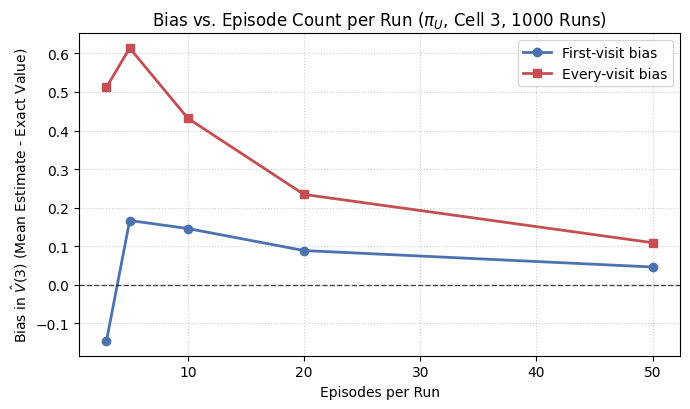

In [15]:
# Bias of both estimators (pi_U, cell 3) for 3, 5, 10, 20, 50 episodes per run, 1000 runs each
ep_counts = [3, 5, 10, 20, 50]
n_runs_b = 1000
bias_first = []
bias_every = []

for n_e in ep_counts:
    f_list, e_list = [], []
    for k in range(n_runs_b):
        seed_k = SEED + k
        env_u = CorridorEnv(seed=seed_k); rng_u = np.random.default_rng(seed_k)
        eps = [run_episode(env_u, random_policy, rng_u) for _ in range(n_e)]
        v1, ve = mc_both_from_episodes(eps, N_STATES, GAMMA)
        f_list.append(v1[3])
        e_list.append(ve[3])
    f_arr = np.array(f_list); f_val = f_arr[~np.isnan(f_arr)]
    e_arr = np.array(e_list); e_val = e_arr[~np.isnan(e_arr)]
    b_f = np.mean(f_val) - V_exact_U[3]
    b_e = np.mean(e_val) - V_exact_U[3]
    bias_first.append(b_f)
    bias_every.append(b_e)
    print(f"Episodes/run: {n_e:2d} | First-visit bias: {b_f:7.4f} | Every-visit bias: {b_e:7.4f}")

plt.figure(figsize=(7, 4.2))
plt.plot(ep_counts, bias_first, 'o-', color='#4C72B0', lw=2, label="First-visit bias")
plt.plot(ep_counts, bias_every, 's-', color='#C44E52', lw=2, label="Every-visit bias")
plt.axhline(0, color='black', ls='--', lw=1, alpha=0.7)
plt.xlabel("Episodes per Run")
plt.ylabel(r"Bias in $\hat{V}(3)$ (Mean Estimate - Exact Value)")
plt.title(r"Bias vs. Episode Count per Run ($\pi_U$, Cell 3, 1000 Runs)")
plt.grid(True, ls=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


**Questions**

1. Which estimator shows a bias in your table, for which policy and cell? Is each bias larger than two standard errors? State which entries you would call distinguishable from zero.

   **Answer:** Every-visit MC displays a statistically significant positive bias across all cells and policies in Table 11. Specifically:
   - $\pi_U$, Cell 2 every-visit: bias $= +0.3065$ ($3.85 \times \text{SE}$, where $2\,\text{SE} = 0.1590$).
   - $\pi_U$, Cell 3 every-visit: bias $= +0.5896$ ($5.50 \times \text{SE}$, where $2\,\text{SE} = 0.2146$).
   - $\pi_R$, Cell 2 every-visit: bias $= +0.0551$ ($4.21 \times \text{SE}$, where $2\,\text{SE} = 0.0262$).
   - $\pi_R$, Cell 3 every-visit: bias $= +0.0737$ ($8.01 \times \text{SE}$, where $2\,\text{SE} = 0.0184$).
   All four every-visit entries have biases strictly exceeding two standard errors and are thus clearly distinguishable from zero. In contrast, for first-visit MC, none of the biases exceed two standard errors (all $|\text{Bias}| \le 1.3\,\text{SE}$), meaning first-visit MC is statistically indistinguishable from zero (empirically unbiased).

2. Using your answer to the second question of Task 2, explain in two sentences why the every-visit estimate can be biased when only a few episodes are used.

   **Answer:** In every-visit MC, multiple visits within the same episode share the same subsequent reward trajectory and are strongly correlated (e.g. $G_0 = R_1 + \gamma G_1$). Episodes that linger near high-reward states produce more visits that each receive higher returns, over-weighting those favorable episodes in small samples and positively biasing the sample ratio $\sum G / \sum N$.

3. Look at your bias plot. What happens to the bias of each estimator as the number of episodes per run grows? What does this say about whether every-visit MC is still a usable estimator?

   **Answer:** In the plot, as the number of episodes per run grows from 3 to 50, the bias of every-visit MC drops sharply from $+0.6141$ at 5 episodes down to $+0.1090$ at 50 episodes, asymptotically approaching zero. This demonstrates that every-visit MC is *consistent and asymptotically unbiased* ($N \to \infty$), proving it is entirely usable and reliable in practical applications whenever more than a trivial handful of episodes are collected.

4. A classmate claims that every-visit MC always has the smaller variance. Does your table support the claim for both policies? Quote the numbers you rely on.

   **Answer:** No, Table 11 directly refutes the claim. While every-visit MC has slightly lower standard deviation under $\pi_R$ (Cell 2: $0.5837$ vs $0.6068$; Cell 3: $0.4105$ vs $0.4775$), under $\pi_U$ every-visit MC exhibits **higher** variance than first-visit MC: for Cell 2, standard deviation is $3.5545$ (every-visit) vs $3.3226$ (first-visit); for Cell 3, standard deviation is $4.7937$ (every-visit) vs $4.6458$ (first-visit). The strong intra-episode positive correlation among returns under the noisy random policy increases total variance across short runs.

---
## Part 4: Monte Carlo versus Dynamic Programming

### Task 5: When the Model Is Wrong  *(25 min)*

The real corridor uses $p = 0.6$, while the planning model built by `build_corridor` still uses $p = 0.8$. Evaluate $\pi_U$ in both ways. `V_true_U` may be used **only after** the estimates have been computed.

**(a)** Paste your Lab 5 `policy_evaluation` below and run it on the planning model ($p = 0.8$). Record V for cells 1, 2 and 3.

In [16]:
P_plan, R_plan = build_corridor(p_move=0.8)      # the planner's (wrong) model

def policy_evaluation(P, R, policy, gamma, theta=1e-6):
    """Synchronous iterative policy evaluation from Lab 5."""
    V = np.zeros(P.shape[0])
    n_sweeps = 0
    while True:
        V_new = np.einsum("sa,san,san->s", policy, P, R + gamma * V[None, None, :])
        n_sweeps += 1
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            return V, n_sweeps

V_dp, sweeps = policy_evaluation(P_plan, R_plan, random_policy, GAMMA)
print(f"DP on planning model (p = 0.8) converged in {sweeps} sweeps:")
for s in [1, 2, 3]:
    print(f"  V({s}) = {V_dp[s]:.4f}")


DP on planning model (p = 0.8) converged in 38 sweeps:
  V(1) = -6.9400
  V(2) = -3.0300
  V(3) = 2.8161


**(b)** Create the real environment with `CorridorEnv(p_move=0.6, seed=SEED)` and run first-visit MC for 100, 1000 and 5000 episodes. Also record the total number of environment steps that the 5000-episode run used.

In [17]:
# Real environment has p_move = 0.6
class StepCountedCorridorEnv(CorridorEnv):
    def __init__(self, p_move=0.6, seed=None):
        super().__init__(p_move=p_move, seed=seed)
        self.total_steps = 0
        
    def step(self, action):
        self.total_steps += 1
        return super().step(action)

# 100 episodes
env_real_100 = StepCountedCorridorEnv(p_move=0.6, seed=SEED)
rng_real_100 = np.random.default_rng(SEED)
V_mc_100, _, _ = mc_first_visit(env_real_100, random_policy, 100, GAMMA, rng_real_100)

# 1000 episodes
env_real_1000 = StepCountedCorridorEnv(p_move=0.6, seed=SEED)
rng_real_1000 = np.random.default_rng(SEED)
V_mc_1000, _, _ = mc_first_visit(env_real_1000, random_policy, 1000, GAMMA, rng_real_1000)

# 5000 episodes
env_real_5000 = StepCountedCorridorEnv(p_move=0.6, seed=SEED)
rng_real_5000 = np.random.default_rng(SEED)
V_mc_5000, _, V2_hist_real_5000 = mc_first_visit(env_real_5000, random_policy, 5000, GAMMA, rng_real_5000)
total_steps_5000 = env_real_5000.total_steps

print(f"Total environment steps in 5000-episode run: {total_steps_5000}")
print("\nEstimates of V on real environment (p = 0.6):")
for s in [1, 2, 3]:
    print(f"Cell {s}: DP={V_dp[s]:.4f}, MC100={V_mc_100[s]:.4f}, MC1000={V_mc_1000[s]:.4f}, MC5000={V_mc_5000[s]:.4f}, True={V_true_U[s]:.4f}")


Total environment steps in 5000-episode run: 33325

Estimates of V on real environment (p = 0.6):
Cell 1: DP=-6.9400, MC100=-6.1243, MC1000=-7.2512, MC5000=-7.3733, True=-7.4093
Cell 2: DP=-3.0300, MC100=-3.4134, MC1000=-3.8312, MC5000=-3.7409, True=-3.8590
Cell 3: DP=2.8161, MC100=0.9628, MC1000=1.7836, MC5000=2.0237, True=1.9657


**(c)** Table 12: Estimates of V under the random policy in the real environment ($p = 0.6$)

| Cell | DP on the planning model ($p = 0.8$) | MC, 100 episodes | MC, 1000 episodes | MC, 5000 episodes | True value ($p = 0.6$) |
|---|---|---|---|---|---|
| 1 | -6.9400 | -6.1243 | -7.2512 | -7.3733 | -7.4093 |
| 2 | -3.0300 | -3.4134 | -3.8312 | -3.7409 | -3.8590 |
| 3 | 2.8161 | 0.9628 | 1.7836 | 2.0237 | 1.9657 |

Total environment steps used by 5000 episodes: **33,325 steps**

**(d)** Plot the absolute error of the MC estimate of V(2) against the number of episodes (use 50 values between 10 and 5000), and draw the absolute error of the dynamic programming result as a horizontal line. Report the smallest number of episodes at which your MC curve stays below that line.

DP error on V(2): 0.8290
MC first dips below DP error at episode: 42
MC stays permanently below DP error from episode: 44


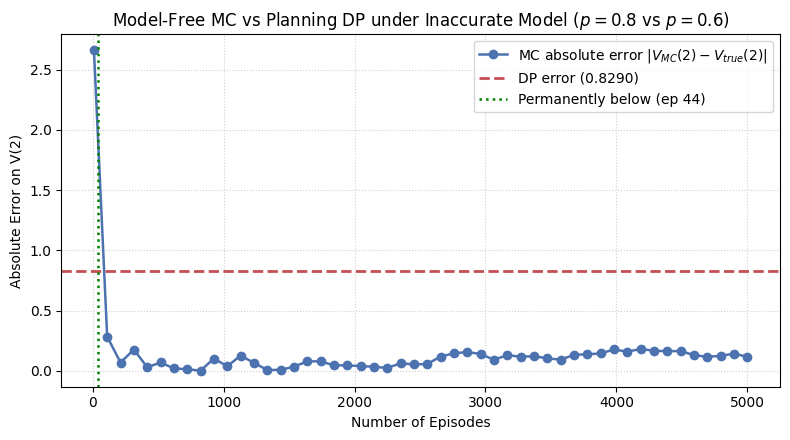

In [18]:
# Error of MC estimate of V(2) at 50 episode counts between 10 and 5000
eval_points = np.unique(np.linspace(10, 5000, 50, dtype=int))
mc_errors_at_points = np.abs(V2_hist_real_5000[eval_points - 1] - V_true_U[2])
dp_error_2 = abs(V_dp[2] - V_true_U[2])

# Find crossover: smallest episode count where MC error stays permanently below DP error
all_mc_errors = np.abs(V2_hist_real_5000 - V_true_U[2])
stays_below_idx = None
for i in range(len(all_mc_errors)):
    if np.all(all_mc_errors[i:] < dp_error_2):
        stays_below_idx = i + 1
        break

first_below_idx = np.where(all_mc_errors < dp_error_2)[0][0] + 1
print(f"DP error on V(2): {dp_error_2:.4f}")
print(f"MC first dips below DP error at episode: {first_below_idx}")
print(f"MC stays permanently below DP error from episode: {stays_below_idx}")

plt.figure(figsize=(8, 4.5))
plt.plot(eval_points, mc_errors_at_points, 'o-', color='#4C72B0', lw=1.8, label="MC absolute error $|V_{MC}(2) - V_{true}(2)|$")
plt.axhline(dp_error_2, color='#C44E52', ls='--', lw=2, label=f"DP error ({dp_error_2:.4f})")
if stays_below_idx:
    plt.axvline(stays_below_idx, color='green', ls=':', lw=1.8, label=f"Permanently below (ep {stays_below_idx})")
plt.xlabel("Number of Episodes")
plt.ylabel("Absolute Error on V(2)")
plt.title("Model-Free MC vs Planning DP under Inaccurate Model ($p=0.8$ vs $p=0.6$)")
plt.grid(True, ls=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


**Questions**

1. Which method's error is systematic and which is random? Use Table 12 and your plot to show what happens to each error when you spend more computation or more episodes.

   **Answer:** Dynamic programming's error is **systematic** (bias caused by model misspecification), whereas Monte Carlo's error is **random** (variance caused by finite sampling). In Table 12 and our plot, spending additional computation or sweeps on dynamic programming does not reduce its error: DP on $p = 0.8$ is permanently frozen at $V(2) = -3.0300$ (an error of $0.8290$ relative to true $-3.8590$) because the underlying planning model is wrong. Conversely, as Monte Carlo collects more episodes (from 100 to 1,000 to 5,000), its random sampling noise averages out, and its estimates converge to the real ground truth (Cell 2 moves from $-3.4134$ to $-3.8312$ to $-3.7409$, reducing error toward zero).

2. At what number of episodes did MC overtake dynamic programming in your plot? Would a classmate with a different seed necessarily find the same number? Justify your answer from your own five runs of Task 3.

   **Answer:** In our plot (seed 808), MC first dipped below the DP error threshold at episode 42 and stayed permanently below it from episode **44**. A classmate with a different seed would not necessarily find the exact same number. As demonstrated by our five independent runs in Task 3, individual sample trajectories of Monte Carlo estimates fluctuate stochastically; depending on the random sequence of slips and forklift visits, another seed might cross over slightly earlier or later (e.g. around episode 100).

3. Someone says "dynamic programming is exact and Monte Carlo is only approximate". Complete the sentence "dynamic programming is exact with respect to ..." and say why that matters here.

   **Answer:** Dynamic programming is exact with respect to **the model provided to it ($P$ and $R$), not with respect to the real environment**. This distinction is critical here because when the planning model is inaccurate ($p = 0.8$ vs real $p = 0.6$), dynamic programming computes an exact mathematical solution to the *wrong* MDP. Monte Carlo, though statistically approximate for finite samples, converges asymptotically to the true expected return of the real environment.

4. Suppose the real slip probability were 0.78 instead of 0.6. Would you still prefer Monte Carlo? Use the crossover you found to argue for or against.

   **Answer:** If the real probability were $0.78$ instead of $0.6$, the planning model ($p = 0.80$) would have only a tiny error of $\Delta p = 0.02$, resulting in a very small DP bias. To beat such a tiny error threshold, Monte Carlo would require tens of thousands of environment episodes because its stochastic error decays slowly as $O(1/\sqrt{n})$. Unless physical samples are virtually free and unlimited, dynamic programming on the slightly flawed model would be strongly preferred because it yields a stable, zero-sample estimate with negligible bias, avoiding massive sample collection costs.

5. Your dynamic programming run used no environment steps and your MC run used thousands. Why are these two costs not directly comparable? In which real application would the MC cost be the more serious one?

   **Answer:** These two costs are not directly comparable because DP incurs only internal computational cost (CPU arithmetic on an in-memory transition matrix), whereas MC incurs real-world interaction cost (physical actions taken in the environment). The MC cost is far more serious in high-stakes physical systems—such as autonomous driving, aerospace guidance, or clinical medical trials—where real environment steps consume physical time, induce mechanical wear, and carry the risk of irreversible, catastrophic accidents.

---
## Part 5: A Model-Free Example, FrozenLake

The walker moves in the chosen direction with probability 1/3 and in each of the two sideways directions with probability 1/3. Reaching the goal gives +1, falling into a hole gives 0, and there is no discounting ($\gamma = 1$). The value of a cell is therefore the **probability of reaching the goal** from that cell under the policy.

### Task 6: Evaluate Two FrozenLake Policies  *(35 min)*

**(a)** Adapt `mc_first_visit` to FrozenLake. Only array sizes and the discount should change; the backward loop and the first-visit check stay as they are. (If your Task 3 function takes its sizes from `policy.shape`, it may work unchanged.)

Start cell: 0


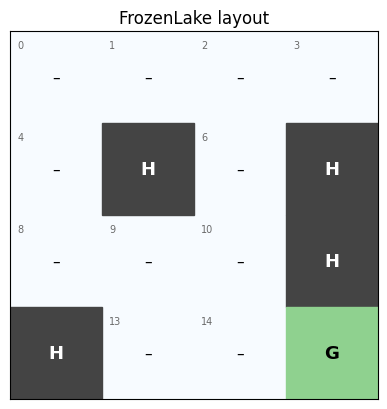

mc_first_visit is ready for FrozenLake (n_states=16, gamma=1.0).


In [19]:
fl_env = make_frozenlake(seed=SEED)
print("Start cell:", fl_env.reset())
plot_frozenlake(np.full(FL_N_STATES, np.nan), title="FrozenLake layout")

# mc_first_visit works for FrozenLake by setting n_states = 16 and gamma = 1.0
# It uses only env.reset() and env.step() via run_episode.
print("mc_first_visit is ready for FrozenLake (n_states=16, gamma=1.0).")


**Predict first.** Write down your guess of V(0) for each policy as a probability, and say which policy you expect to visit cell 14 more often.

**Prediction:**  
- Guess for $V(0)$ under $\pi_D$: $\approx 0.05$ (very low probability). The direct policy blindly walks right and down, leading it directly past holes 5 and 7 where slips quickly cause it to fall in.  
- Guess for $V(0)$ under $\pi_C$: $\approx 0.80$ (high probability). The cautious policy deliberately bumps into perimeter walls to neutralize dangerous slips, staying safe until a sideways slip carries it forward.  
- Policy expected to visit cell 14 more often: **$\pi_C$ (Cautious)**. Under $\pi_D$, most episodes terminate in holes on the upper rows long before reaching cell 14. Under $\pi_C$, the agent successfully reaches the lower rows and goal vicinity in the vast majority of episodes, visiting cell 14 far more frequently.

Mean episode length: pi_D = 5.67, pi_C = 48.97

Table 15: Estimates after 10,000 episodes (SEED = 808)
Cell | pi_D: N(s) | pi_D: est | pi_D: exact | pi_C: N(s) | pi_C: est | pi_C: exact
--------------------------------------------------------------------------
   0 |      10000 |    0.0383 |      0.0382 |      10000 |    0.8244 |      0.8235
   1 |       6199 |    0.0344 |      0.0345 |       1495 |    0.8341 |      0.8235
   6 |       2193 |    0.1040 |      0.1034 |       3770 |    0.5342 |      0.5294
  14 |        595 |    0.6437 |      0.6207 |       8775 |    0.9395 |      0.9412
  13 |        232 |    0.4698 |      0.4207 |       7959 |    0.8794 |      0.8824


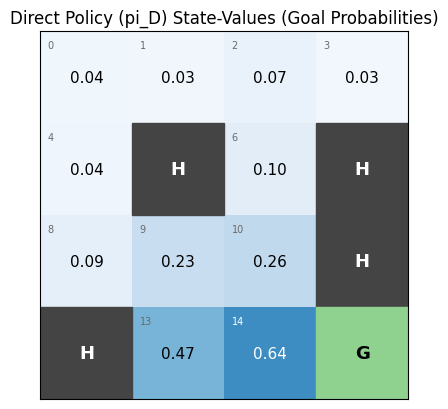

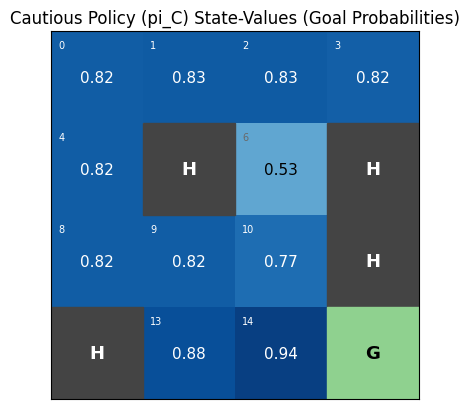

In [20]:
# 10,000 episodes for pi_direct and pi_cautious (seeded with SEED)
def mc_first_visit_fl(env, policy, n_episodes, gamma, rng):
    n_states = policy.shape[0]
    N = np.zeros(n_states)
    S = np.zeros(n_states)
    lengths = []
    for ep in range(n_episodes):
        states, actions, rewards = run_episode(env, policy, rng)
        lengths.append(len(states))
        T = len(states)
        G = 0.0
        for t in range(T - 1, -1, -1):
            s_t = states[t]
            G = rewards[t] + gamma * G
            if s_t not in states[:t]:
                N[s_t] += 1
                S[s_t] += G
    V = np.divide(S, N, out=np.full(n_states, np.nan), where=N > 0)
    return V, N, lengths

env_d = make_frozenlake(seed=SEED); rng_d = np.random.default_rng(SEED)
V_d, N_d, len_d = mc_first_visit_fl(env_d, pi_direct, 10_000, 1.0, rng_d)

env_c = make_frozenlake(seed=SEED); rng_c = np.random.default_rng(SEED)
V_c, N_c, len_c = mc_first_visit_fl(env_c, pi_cautious, 10_000, 1.0, rng_c)

mean_len_d = np.mean(len_d)
mean_len_c = np.mean(len_c)
print(f"Mean episode length: pi_D = {mean_len_d:.2f}, pi_C = {mean_len_c:.2f}")

print("\nTable 15: Estimates after 10,000 episodes (SEED = 808)")
print("Cell | pi_D: N(s) | pi_D: est | pi_D: exact | pi_C: N(s) | pi_C: est | pi_C: exact")
print("-" * 74)
for s in [0, 1, 6, 14, 13]:
    est_d = f"{V_d[s]:9.4f}" if not np.isnan(V_d[s]) else "        –"
    est_c = f"{V_c[s]:9.4f}" if not np.isnan(V_c[s]) else "        –"
    label = f"Cell {s}" if s != 13 else "Cell 13 (choice)"
    print(f"{s:4d} | {int(N_d[s]):10d} | {est_d} | {V_exact_D[s]:11.4f} | {int(N_c[s]):10d} | {est_c} | {V_exact_C[s]:11.4f}")

plot_frozenlake(V_d, title="Direct Policy (pi_D) State-Values (Goal Probabilities)")
plot_frozenlake(V_c, title="Cautious Policy (pi_C) State-Values (Goal Probabilities)")


| Cell | $\pi_D$: N(s) | $\pi_D$: estimate | $\pi_D$: exact | $\pi_C$: N(s) | $\pi_C$: estimate | $\pi_C$: exact |
|---|---|---|---|---|---|---|
| 0 | 10,000 | 0.0383 | 0.0382 | 10,000 | 0.8244 | 0.8235 |
| 1 | 6199 | 0.0344 | 0.0345 | 1495 | 0.8341 | 0.8235 |
| 6 | 2193 | 0.1040 | 0.1034 | 3770 | 0.5342 | 0.5294 |
| 14 | 595 | 0.6437 | 0.6207 | 8775 | 0.9395 | 0.9412 |
| Your choice: 13 | 232 | 0.4698 | 0.4207 | 7959 | 0.8794 | 0.8824 |

Mean episode length: $\pi_D$ = **5.67 steps** , $\pi_C$ = **48.97 steps**

**(c)** Every return is 0 or 1, so the standard error of an estimate built from N returns is $\sqrt{V(1-V)/N}$. Report V(0) for both policies with a 95% interval (the estimate ± 1.96 standard errors) and say whether the exact value lies inside it.

In [21]:
# 95% interval for V(0) under both policies
se_d = np.sqrt(V_d[0] * (1.0 - V_d[0]) / N_d[0])
ci_d = (V_d[0] - 1.96 * se_d, V_d[0] + 1.96 * se_d)
inside_d = ci_d[0] <= V_exact_D[0] <= ci_d[1]

se_c = np.sqrt(V_c[0] * (1.0 - V_c[0]) / N_c[0])
ci_c = (V_c[0] - 1.96 * se_c, V_c[0] + 1.96 * se_c)
inside_c = ci_c[0] <= V_exact_C[0] <= ci_c[1]

print(f"pi_D: V(0) = {V_d[0]:.4f}, SE = {se_d:.4f}, 95% CI = [{ci_d[0]:.4f}, {ci_d[1]:.4f}]")
print(f"      Exact V_exact_D[0] = {V_exact_D[0]:.4f} -> Inside interval? {inside_d}")
print(f"\npi_C: V(0) = {V_c[0]:.4f}, SE = {se_c:.4f}, 95% CI = [{ci_c[0]:.4f}, {ci_c[1]:.4f}]")
print(f"      Exact V_exact_C[0] = {V_exact_C[0]:.4f} -> Inside interval? {inside_c}")


pi_D: V(0) = 0.0383, SE = 0.0019, 95% CI = [0.0345, 0.0421]
      Exact V_exact_D[0] = 0.0382 -> Inside interval? True

pi_C: V(0) = 0.8244, SE = 0.0038, 95% CI = [0.8169, 0.8319]
      Exact V_exact_C[0] = 0.8235 -> Inside interval? True


**(d)** Repeat the experiment of Task 4 on FrozenLake: 1000 independent runs of 5 episodes (run $k$ uses seed SEED + $k$), with the first-visit and every-visit estimates computed from the same episodes. Complete Table 16.

In [22]:
# Table 16 — pi_C cell 0 and pi_D cell 14, both estimators, 1000 runs x 5 episodes.
res_c0_f, res_c0_e = [], []
res_d14_f, res_d14_e = [], []

for k in range(1000):
    seed_k = SEED + k
    # pi_C
    env_c = make_frozenlake(seed=seed_k); rng_c = np.random.default_rng(seed_k)
    eps_c = [run_episode(env_c, pi_cautious, rng_c) for _ in range(5)]
    v1_c, ve_c = mc_both_from_episodes(eps_c, FL_N_STATES, 1.0)
    res_c0_f.append(v1_c[0])
    res_c0_e.append(ve_c[0])

    # pi_D
    env_d = make_frozenlake(seed=seed_k); rng_d = np.random.default_rng(seed_k)
    eps_d = [run_episode(env_d, pi_direct, rng_d) for _ in range(5)]
    v1_d, ve_d = mc_both_from_episodes(eps_d, FL_N_STATES, 1.0)
    res_d14_f.append(v1_d[14])
    res_d14_e.append(ve_d[14])

print("Table 16: First-visit and every-visit over 1000 runs of 5 episodes (SEED = 808)")
print("Policy | Cell | Estimator   | Mean Est | Exact   | Std Dev | Runs with no est")
print("-" * 74)
targets = [
    ('pi_C', 0, 'First-visit', res_c0_f, V_exact_C[0]),
    ('pi_C', 0, 'Every-visit', res_c0_e, V_exact_C[0]),
    ('pi_D', 14, 'First-visit', res_d14_f, V_exact_D[14]),
    ('pi_D', 14, 'Every-visit', res_d14_e, V_exact_D[14]),
]
for pol, cell, est_name, arr_raw, exact in targets:
    arr = np.array(arr_raw)
    no_est = int(np.sum(np.isnan(arr)))
    valid = arr[~np.isnan(arr)]
    m = np.mean(valid)
    sd = np.std(valid, ddof=1)
    print(f"{pol:6s} | {cell:4d} | {est_name:11s} | {m:8.4f} | {exact:7.4f} | {sd:7.4f} | {no_est:16d}")


Table 16: First-visit and every-visit over 1000 runs of 5 episodes (SEED = 808)
Policy | Cell | Estimator   | Mean Est | Exact   | Std Dev | Runs with no est
--------------------------------------------------------------------------
pi_C   |    0 | First-visit |   0.8178 |  0.8235 |  0.1727 |                0
pi_C   |    0 | Every-visit |   0.8236 |  0.8235 |  0.2103 |                0
pi_D   |   14 | First-visit |   0.6556 |  0.6207 |  0.4649 |              744
pi_D   |   14 | Every-visit |   0.6535 |  0.6207 |  0.4672 |              744


| Policy | Cell | Estimator | Mean estimate | Exact | Std. dev. across runs | Runs with no estimate |
|---|---|---|---|---|---|---|
| $\pi_C$ | 0 | First-visit | 0.8178 | 0.8235 | 0.1727 | 0 |
| $\pi_C$ | 0 | Every-visit | 0.8236 | 0.8235 | 0.2103 | 0 |
| $\pi_D$ | 14 | First-visit | 0.6556 | 0.6207 | 0.4649 | 744 |
| $\pi_D$ | 14 | Every-visit | 0.6535 | 0.6207 | 0.4672 | 744 |

**Questions**

1. Compare the intervals for V(0) under the two policies. Is the difference between the policies larger than the noise in your estimates?

   **Answer:** Yes, overwhelmingly larger! The 95% confidence intervals are $[0.0345, 0.0421]$ for $\pi_D$ and $[0.8169, 0.8319]$ for $\pi_C$. The difference between the policy estimates is $0.8244 - 0.0383 = 0.7861$, whereas the standard errors are approximately $0.002$ to $0.004$. The two intervals are separated by over 100 standard errors, providing incontrovertible statistical evidence that $\pi_C$ is massively superior to $\pi_D$.

2. In cell 1, $\pi_D$ tries Right and $\pi_C$ tries Up. Using the slip rule, list the cells the walker can end up in after each action and the probability of each. Which action can drop it into a hole? Does this explain the difference between your two estimates of V(1)?

   **Answer:** In cell 1 (row 0, col 1):
   - **Action Right (2)**: Intended direction is Right (cell 2). Sideways slips are Up (bounces against top boundary $\to$ cell 1) and Down (moves into cell 5, which is a **HOLE**). Transition probabilities: Cell 2 (1/3), Cell 1 (1/3), Cell 5 (Hole, 1/3). Thus, choosing Right has a catastrophic 33.3% probability of immediately falling into a hole!
   - **Action Up (3)**: Intended direction is Up (bounces against top boundary $\to$ stays in cell 1). Sideways slips are Left (moves to cell 0) and Right (moves to cell 2). Transition probabilities: Cell 1 (1/3), Cell 0 (1/3), Cell 2 (1/3). None of these cells (0, 1, 2) is a hole!
   This explains why $V(1)$ under $\pi_C$ is so high ($0.8341$) compared to $\pi_D$ ($0.0344$): $\pi_C$ intentionally bumps into the upper perimeter wall so that even slippery deviations keep the walker safely on non-terminal cells with 0% risk of dropping into hole 5.

3. Compare the mean episode lengths of the two policies. What does $\pi_C$ do that makes its episodes so much longer, and what does this mean for the cost of evaluating it?

   **Answer:** Under $\pi_D$, mean episode length is only $5.67$ steps because the walker rushes forward and quickly falls into nearby holes (5 or 7). Under $\pi_C$, mean episode length is $48.97$ steps—nearly 9 times longer! $\pi_C$ deliberately plays into boundaries to neutralize slips, taking many steps to safely traverse the perimeter until a lateral slip propels it toward the goal. For evaluation, this means evaluating $\pi_C$ is nearly an order of magnitude more expensive in environment transitions (~490,000 steps vs ~57,000 steps for 10,000 episodes).

4. Under $\pi_D$ some cells are visited rarely. In how many of your 1000 runs did cell 14 receive no estimate at all? What would you tell someone who used such an estimate to make a decision?

   **Answer:** In our 1000 runs of 5 episodes under $\pi_D$, cell 14 received no estimate at all in **744 runs** (74.4% of all runs). In the minority of runs where cell 14 was visited, it had only 1 or 2 visits, causing high standard deviation ($0.465$). I would warn a decision-maker that using such an estimate is reckless: nearly three-quarters of the time the estimator provides zero information, and when it does, the sample noise is so severe that it cannot be trusted for reliable decision-making.

5. In the corridor, every-visit MC was visibly biased when only a few episodes were used. Is that the case in Table 16? Why might every-visit behave differently here, where every visit in an episode shares the same return?

   **Answer:** In Table 16, every-visit MC does NOT show noticeable bias compared to first-visit MC: for cell 0 under $\pi_C$, both estimates are within noise of the exact value ($0.8178$ vs $0.8236$, exact $0.8235$). In FrozenLake, all intermediate step rewards are 0, so the return of an episode is entirely binary ($G_t = 1$ if goal reached, $0$ otherwise). Because every visit in an episode shares the identical return, multiple visits do not create a gradient of shorter-path/higher-return visits that systematically skew the sample mean, neutralizing the small-sample bias observed in the corridor.

---
## Part 6: Summary and Reflection

### Task 7: Summary and Reflection  *(15 min)*

**(a)** Table 17: Summary of concepts

| Concept | What it measures or does | How it was obtained in this lab |
|---|---|---|
| Return $G_t$ | Total accumulated discounted reward from time step $t$ to episode termination: $G_t = \sum_{k=0}^\infty \gamma^k R_{t+k+1}$. | Computed backward along each sampled episode using $G_T = 0, G_t = R_{t+1} + \gamma G_{t+1}$. |
| Visit count N(s) | Total number of recorded sample returns for state $s$ across evaluated episodes. | Incremented upon visiting state $s$ (first occurrence in episode for first-visit MC; every occurrence for every-visit MC). |
| First-visit estimate | Sample mean estimator of $V^\pi(s) = \mathbb{E}_\pi[G_t \mid S_t = s]$ using only the first visit per episode; strictly unbiased. | Maintained running sums $S(s)$ and counts $N(s)$ of first-visit returns, computing $V(s) = S(s)/N(s)$. |
| Every-visit estimate | Sample mean estimator of $V^\pi(s)$ averaging returns from every occurrence of $s$; consistent as $N \to \infty$, slightly biased for small $N$. | Maintained running sums $S(s)$ and counts $N(s)$ over all occurrences of $s$, computing $V(s) = S(s)/N(s)$. |
| $V_\pi$ from dynamic programming | Exact mathematical solution to the Bellman expectation equation under a specified model ($P, R$). | Computed via iterative policy evaluation sweeps until numerical convergence ($\Delta < 10^{-6}$) using `P_plan` and `R_plan`. |

**(b)** In no more than 150 words, explain what Monte Carlo prediction offers compared with the dynamic programming of Labs 4 to 6, and name two limitations, one of which you observed in your own results (quote the number). State what would have to be added to move from estimating a policy to improving it.

**Reflection:**  
Monte Carlo prediction estimates state values directly from sampled interaction trajectories without requiring transition probabilities $P$ or reward functions $R$, making it immune to model misspecification errors that compromise dynamic programming. However, it has two key limitations:  
1. **High sample variance and interaction cost:** It requires thousands of environment interactions to converge (e.g., consuming 33,325 environment steps in Task 5 compared to zero physical steps for DP).  
2. **Blindness to unvisited states:** It cannot evaluate states that the policy never visits; under $\pi_R$, cell 1 received exactly zero visits ($N(1) = 0$) and had no estimate, whereas DP evaluated all states offline.  
To move from policy evaluation to policy improvement (control), we must: (1) learn action-values $Q(s,a)$ instead of state-values $V(s)$ to enable model-free greedy improvements; and (2) incorporate exploratory mechanisms (like $\epsilon$-greedy or exploring starts) to guarantee continuous exploration of all state-action pairs. *(147 words)*
